In [26]:
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from matplotlib.colors import ListedColormap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [27]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
DATA_FILE = Path("data_banknote_authentication.txt")
columns = ["variance", "skewness", "curtosis", "entropy", "class"]

if not DATA_FILE.exists():
    try:
        urllib.request.urlretrieve(DATA_URL, DATA_FILE)
        print("Downloaded dataset.")
    except Exception as e:
        raise RuntimeError(
            "Could not download the dataset. Download data_banknote_authentication.txt "
            "from the UCI Banknote Authentication dataset and place it beside this notebook."
        ) from e

df = pd.read_csv(DATA_FILE, header=None, names=columns)
print("Dataset shape:", df.shape)
display(df.head())
display(df["class"].value_counts().rename("count"))

Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


,count
class,
0,762
1,610


The dataset has four numeric input features and a binary target. For the required 2D decision-boundary plots, this notebook uses **variance** and **skewness**. The final comparison uses **all four features**.

In [28]:
FEATURES_2D = ["variance", "skewness"]
X2 = df[FEATURES_2D].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

X2_train, X2_test, y_train, y_test = train_test_split(
    X2, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X2_train), "| Test rows:", len(X2_test))

Training rows: 1029 | Test rows: 343


In [29]:
def gini_impurity(y):
    """Calculate Gini impurity."""
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / counts.sum()

    return float(1 - np.sum(probabilities ** 2))


def entropy(y):
    """Calculate entropy using log base 2."""
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / counts.sum()

    return float(-np.sum(probabilities * np.log2(probabilities)))


class ManualDecisionTree:
    """Decision Tree classifier implemented using NumPy."""

    def __init__(
        self,
        criterion="gini",
        max_depth=4,
        min_samples_split=2,
        min_samples_leaf=1,
        min_impurity_decrease=1e-10
    ):
        if criterion not in ("gini", "entropy"):
            raise ValueError("criterion must be 'gini' or 'entropy'")

        if max_depth is not None and (
            not isinstance(max_depth, (int, np.integer)) or max_depth < 0
        ):
            raise ValueError("max_depth must be a non-negative integer or None")

        if min_samples_split < 2:
            raise ValueError("min_samples_split must be at least 2")

        if min_samples_leaf < 1:
            raise ValueError("min_samples_leaf must be at least 1")

        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease

        self.root = None
        self.n_features_in_ = None

    def _impurity(self, y):
        if self.criterion == "gini":
            return gini_impurity(y)
        return entropy(y)

    def _best_split(self, X, y):
        n_samples = len(y)
        parent_impurity = self._impurity(y)

        best_gain = 0.0
        best_feature = None
        best_threshold = None

        for feature in range(X.shape[1]):
            values = np.unique(X[:, feature])

            if len(values) < 2:
                continue

            thresholds = (values[:-1] + values[1:]) / 2.0

            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold

                n_left = int(left_mask.sum())
                n_right = n_samples - n_left

                if (
                    n_left < self.min_samples_leaf
                    or n_right < self.min_samples_leaf
                ):
                    continue

                y_left = y[left_mask]
                y_right = y[~left_mask]

                weighted_impurity = (
                    (n_left / n_samples) * self._impurity(y_left)
                    + (n_right / n_samples) * self._impurity(y_right)
                )

                gain = parent_impurity - weighted_impurity

                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature
                    best_threshold = float(threshold)

        if (
            best_feature is None
            or best_gain < self.min_impurity_decrease
        ):
            return None

        return best_feature, best_threshold, best_gain

    def _build(self, X, y, depth):
        values, counts = np.unique(y, return_counts=True)

        node = {
            "prediction": int(values[np.argmax(counts)]),
            "samples": len(y),
            "impurity": self._impurity(y),
            "depth": depth
        }

        stop_at_depth = (
            self.max_depth is not None
            and depth >= self.max_depth
        )

        if (
            len(values) == 1
            or stop_at_depth
            or len(y) < self.min_samples_split
        ):
            node["leaf"] = True
            return node

        split = self._best_split(X, y)

        if split is None:
            node["leaf"] = True
            return node

        feature, threshold, gain = split
        mask = X[:, feature] <= threshold

        if mask.sum() == 0 or (~mask).sum() == 0:
            node["leaf"] = True
            return node

        node.update({
            "leaf": False,
            "feature": feature,
            "threshold": threshold,
            "gain": gain
        })

        node["left"] = self._build(
            X[mask], y[mask], depth + 1
        )

        node["right"] = self._build(
            X[~mask], y[~mask], depth + 1
        )

        return node

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)

        if X.ndim != 2:
            raise ValueError("X must be a 2D array")

        if y.ndim != 1 or len(X) != len(y):
            raise ValueError("y must be 1D and match the number of rows in X")

        if len(y) == 0 or X.shape[1] == 0:
            raise ValueError("X and y must not be empty")

        if not np.all(np.isfinite(X)):
            raise ValueError("X must contain only finite numeric values")

        self.n_features_in_ = X.shape[1]
        self.root = self._build(X, y, 0)

        return self

    def _predict_one(self, row, node):
        while not node["leaf"]:
            if row[node["feature"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]

        return node["prediction"]

    def predict(self, X):
        if self.root is None:
            raise ValueError("Fit the model before calling predict")

        X = np.asarray(X, dtype=float)

        if X.ndim != 2:
            raise ValueError("X must be a 2D array")

        if X.shape[1] != self.n_features_in_:
            raise ValueError("X has a different number of features than training data")

        if not np.all(np.isfinite(X)):
            raise ValueError("X must contain only finite numeric values")

        return np.array([
            self._predict_one(row, self.root)
            for row in X
        ], dtype=int)


manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=4
)

manual_tree.fit(X2_train, y_train)

manual_tree_predictions = manual_tree.predict(X2_test)

print(
    "Manual tree test accuracy:",
    round(accuracy_score(y_test, manual_tree_predictions), 4)
)


Manual tree test accuracy: 0.9213


In [30]:
def print_tree(node, feature_names, indent=""):
    if node["leaf"]:
        print(f"{indent}Predict class {node['prediction']} (samples={node['samples']})")
        return
    name = feature_names[node["feature"]]
    print(f"{indent}if {name} <= {node['threshold']:.4f}:")
    print_tree(node["left"], feature_names, indent + "  ")
    print(f"{indent}else:")
    print_tree(node["right"], feature_names, indent + "  ")

print_tree(manual_tree.root, FEATURES_2D)

if variance <= 0.7651:
  if skewness <= 5.1608:
    if variance <= 0.3202:
      if variance <= -0.4586:
        Predict class 1 (samples=328)
      else:
        Predict class 1 (samples=62)
    else:
      if skewness <= 0.9819:
        Predict class 0 (samples=27)
      else:
        Predict class 1 (samples=19)
  else:
    if variance <= -3.4311:
      if variance <= -4.3819:
        Predict class 1 (samples=25)
      else:
        Predict class 0 (samples=2)
    else:
      if skewness <= 5.3646:
        Predict class 0 (samples=2)
      else:
        Predict class 0 (samples=90)
else:
  if variance <= 1.7907:
    if skewness <= 4.8979:
      if skewness <= 0.1376:
        Predict class 0 (samples=22)
      else:
        Predict class 1 (samples=47)
    else:
      Predict class 0 (samples=41)
  else:
    if variance <= 2.3921:
      if variance <= 2.3823:
        Predict class 0 (samples=56)
      else:
        Predict class 1 (samples=1)
    else:
      Predict class 0 (samples=

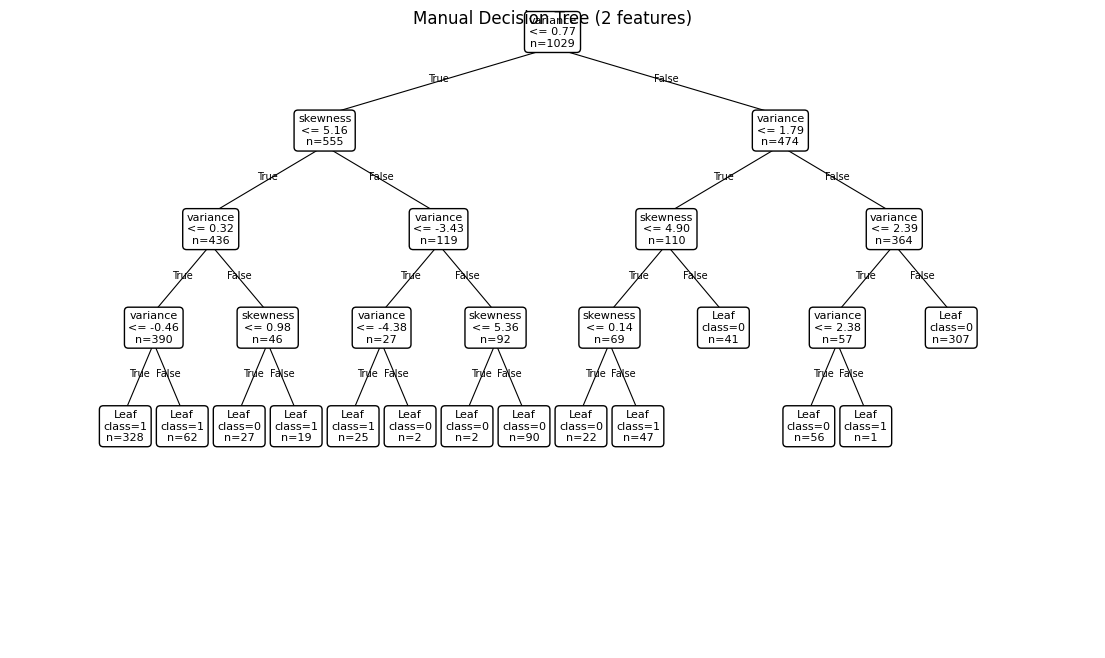

In [31]:
def draw_manual_tree(node, feature_names, ax, x=0.5, y_pos=1.0, x_span=0.42, depth=0, max_depth=5):
    if node["leaf"]:
        label = f"Leaf\nclass={node['prediction']}\nn={node['samples']}"
    else:
        label = f"{feature_names[node['feature']]}\n<= {node['threshold']:.2f}\nn={node['samples']}"
    ax.text(x, y_pos, label, ha="center", va="center", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="black"),
            transform=ax.transAxes)
    if not node["leaf"] and depth < max_depth:
        child_y = y_pos - 0.16
        for child, child_x, edge_label in [
            (node["left"], x - x_span/2, "True"),
            (node["right"], x + x_span/2, "False")
        ]:
            ax.plot([x, child_x], [y_pos - 0.025, child_y + 0.025],
                    color="black", linewidth=0.8, transform=ax.transAxes)
            ax.text((x+child_x)/2, (y_pos+child_y)/2, edge_label, fontsize=7,
                    transform=ax.transAxes, ha="center")
            draw_manual_tree(child, feature_names, ax, child_x, child_y, x_span/2,
                             depth+1, max_depth)

fig, ax = plt.subplots(figsize=(14, 8))
ax.set_axis_off()
draw_manual_tree(manual_tree.root, FEATURES_2D, ax)
ax.set_title("Manual Decision Tree (2 features)")
plt.show()

Manual tree accuracy: 0.9213
Scikit-learn tree accuracy: 0.9213


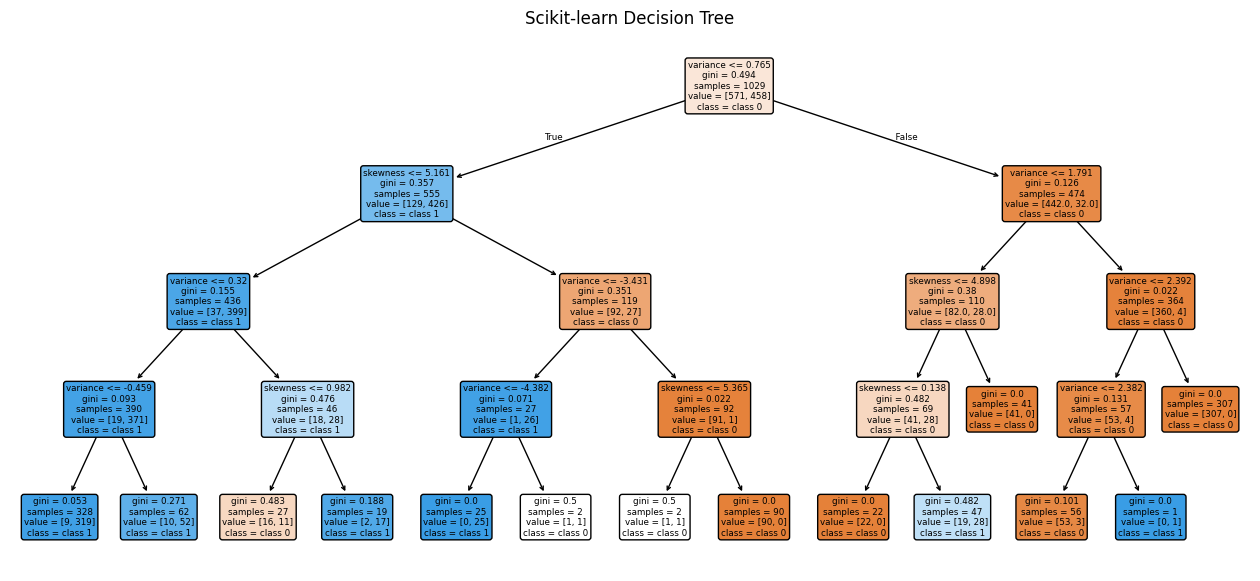

In [32]:
sk_tree = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE)
sk_tree.fit(X2_train, y_train)
sk_tree_pred = sk_tree.predict(X2_test)

print("Manual tree accuracy:", round(accuracy_score(y_test, manual_tree_predictions), 4))
print("Scikit-learn tree accuracy:", round(accuracy_score(y_test, sk_tree_pred), 4))

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(sk_tree, feature_names=FEATURES_2D, class_names=["class 0", "class 1"],
          filled=True, rounded=True, ax=ax)
ax.set_title("Scikit-learn Decision Tree")
plt.show()

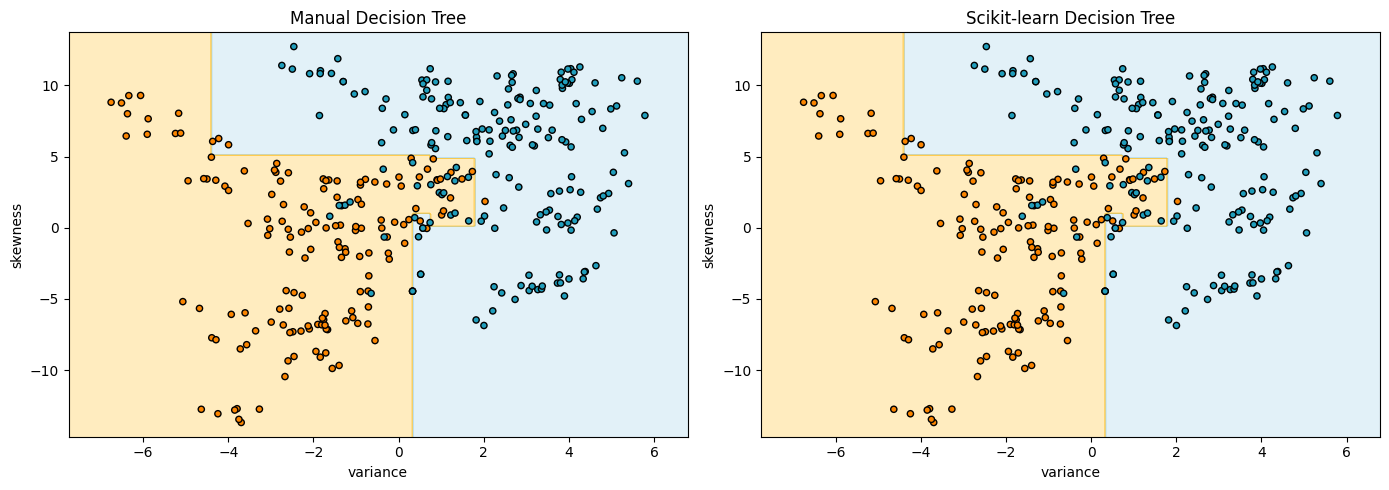

In [33]:
def plot_boundary(model, X, y, title, feature_names=FEATURES_2D, ax=None, show_points=True):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                         np.linspace(y_min, y_max, 250))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap=ListedColormap(["#8ecae6", "#ffb703"]))
    if show_points:
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap=ListedColormap(["#219ebc", "#fb8500"]),
                   edgecolor="k", s=20)
    ax.set_xlabel(feature_names[0])
    ax.set_ylabel(feature_names[1])
    ax.set_title(title)
    return ax

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_boundary(manual_tree, X2_test, y_test, "Manual Decision Tree", ax=axes[0])
plot_boundary(sk_tree, X2_test, y_test, "Scikit-learn Decision Tree", ax=axes[1])
plt.tight_layout()
plt.show()

In [34]:
tree_rows = []
for criterion in ["gini", "entropy"]:
    for depth in [1, 2, 3, 4, 6, None]:
        model = ManualDecisionTree(criterion=criterion, max_depth=depth)
        t0 = time.perf_counter()
        model.fit(X2_train, y_train)
        train_time = time.perf_counter() - t0
        t0 = time.perf_counter()
        pred = model.predict(X2_test)
        pred_time = time.perf_counter() - t0
        tree_rows.append({
            "model": "Manual Tree", "criterion": criterion, "max_depth": str(depth),
            "accuracy": accuracy_score(y_test, pred), "train_time_s": train_time,
            "prediction_time_s": pred_time
        })

tree_experiments = pd.DataFrame(tree_rows)
display(tree_experiments.sort_values("accuracy", ascending=False).reset_index(drop=True))

,model,criterion,max_depth,accuracy,train_time_s,prediction_time_s
0,Manual Tree,entropy,6,0.927114,1.068115,0.001100
1,Manual Tree,gini,None,0.927114,0.818355,0.000686
2,Manual Tree,gini,6,0.924198,0.718857,0.000620
3,Manual Tree,gini,4,0.921283,0.590017,0.000523
4,Manual Tree,entropy,None,0.918367,0.895664,0.000622
5,Manual Tree,gini,3,0.906706,0.504535,0.000626
6,Manual Tree,entropy,4,0.897959,0.885606,0.000991
7,Manual Tree,entropy,3,0.897959,0.752478,0.000906
8,Manual Tree,entropy,2,0.865889,0.491868,0.000750
9,Manual Tree,gini,2,0.865889,0.317762,0.000367


In [35]:
class ManualLinearSVM:
    """Linear soft-margin SVM trained with subgradient descent on hinge loss.

    Objective: 0.5 * ||w||^2 + C * mean(max(0, 1 - y*(Xw+b)))
    Labels must be -1 and +1.
    """
    def __init__(self, C=1.0, learning_rate=0.001, n_iter=3000):
        self.C = float(C)
        self.learning_rate = float(learning_rate)
        self.n_iter = int(n_iter)
        self.w = None
        self.b = 0.0
        self.loss_history = []

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        if not np.all(np.isin(np.unique(y), [-1, 1])):
            raise ValueError("SVM labels must be -1 and +1")
        n, p = X.shape
        self.w = np.zeros(p, dtype=float)
        self.b = 0.0
        for epoch in range(self.n_iter):
            margins = y * (X @ self.w + self.b)
            active = margins < 1
            grad_w = self.w - self.C * np.mean((y[active, None] * X[active]), axis=0) if np.any(active) else self.w.copy()
            grad_b = -self.C * np.mean(y[active]) if np.any(active) else 0.0
            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b
            if epoch % 50 == 0 or epoch == self.n_iter - 1:
                current_margins = y * (X @ self.w + self.b)
                hinge = np.maximum(0, 1 - current_margins).mean()
                self.loss_history.append(0.5 * np.dot(self.w, self.w) + self.C * hinge)
        return self

    def decision_function(self, X):
        return np.asarray(X, float) @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

Manual linear SVM accuracy: 0.8805
Learned weights: [-0.56453512 -0.26279641]
Learned bias: -0.269


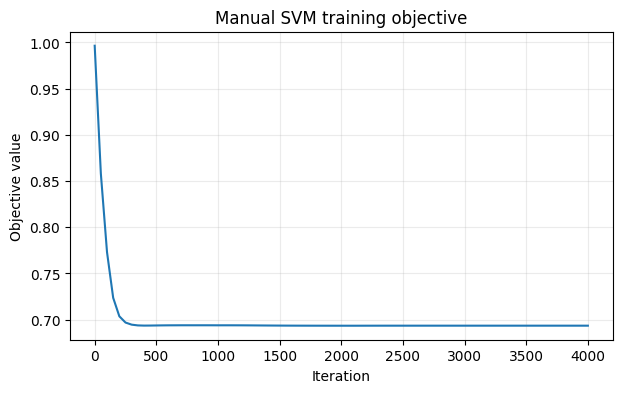

In [36]:
scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)
y_train_svm = np.where(y_train == 1, 1, -1)
y_test_svm = np.where(y_test == 1, 1, -1)

manual_svm = ManualLinearSVM(C=1.0, learning_rate=0.005, n_iter=4000)
manual_svm.fit(X2_train_scaled, y_train_svm)
manual_svm_pred = manual_svm.predict(X2_test_scaled)

print("Manual linear SVM accuracy:", round(accuracy_score(y_test_svm, manual_svm_pred), 4))
print("Learned weights:", manual_svm.w)
print("Learned bias:", round(manual_svm.b, 4))

plt.figure(figsize=(7, 4))
plt.plot(np.arange(len(manual_svm.loss_history)) * 50, manual_svm.loss_history)
plt.xlabel("Iteration")
plt.ylabel("Objective value")
plt.title("Manual SVM training objective")
plt.grid(alpha=0.25)
plt.show()

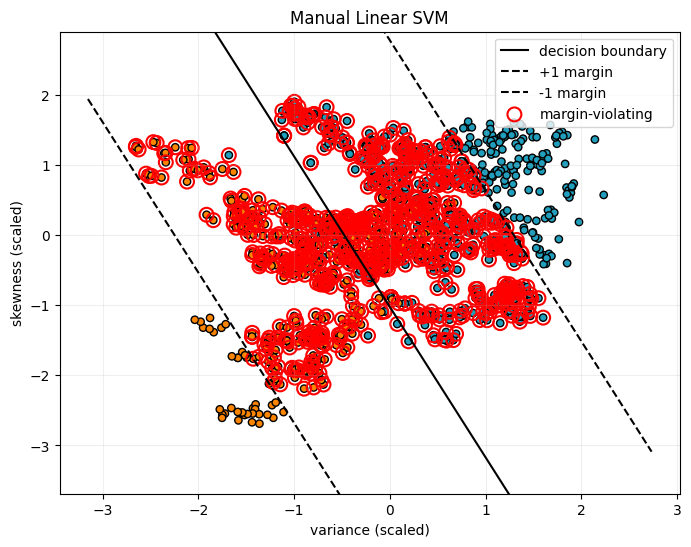

In [37]:
def plot_manual_svm(X_scaled, y_pm, model, title="Manual Linear SVM"):
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_pm,
               cmap=ListedColormap(["#219ebc", "#fb8500"]), edgecolor="k", s=28)
    x_values = np.linspace(X_scaled[:, 0].min()-0.5, X_scaled[:, 0].max()+0.5, 300)
    if abs(model.w[1]) < 1e-12:
        ax.axvline(-model.b / model.w[0], label="decision boundary")
        ax.set_xlabel("variance (scaled)")
        ax.set_ylabel("skewness (scaled)")
    else:
        decision_y = -(model.w[0] * x_values + model.b) / model.w[1]
        margin_plus = -(model.w[0] * x_values + model.b - 1) / model.w[1]
        margin_minus = -(model.w[0] * x_values + model.b + 1) / model.w[1]
        ax.plot(x_values, decision_y, "k-", label="decision boundary")
        ax.plot(x_values, margin_plus, "k--", label="+1 margin")
        ax.plot(x_values, margin_minus, "k--", label="-1 margin")
        ax.set_ylim(X_scaled[:, 1].min()-1, X_scaled[:, 1].max()+1)
        ax.set_xlabel("variance (scaled)")
        ax.set_ylabel("skewness (scaled)")
    margins = y_pm * model.decision_function(X_scaled)
    violating = margins < 1
    ax.scatter(X_scaled[violating, 0], X_scaled[violating, 1],
               s=100, facecolors="none", edgecolors="red", linewidths=1.5,
               label="margin-violating")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.2)
    plt.show()

plot_manual_svm(X2_train_scaled, y_train_svm, manual_svm)

Manual linear SVM accuracy: 0.8805
Scikit-learn linear SVM accuracy: 0.8892
Scikit-learn training time (s): 0.019452


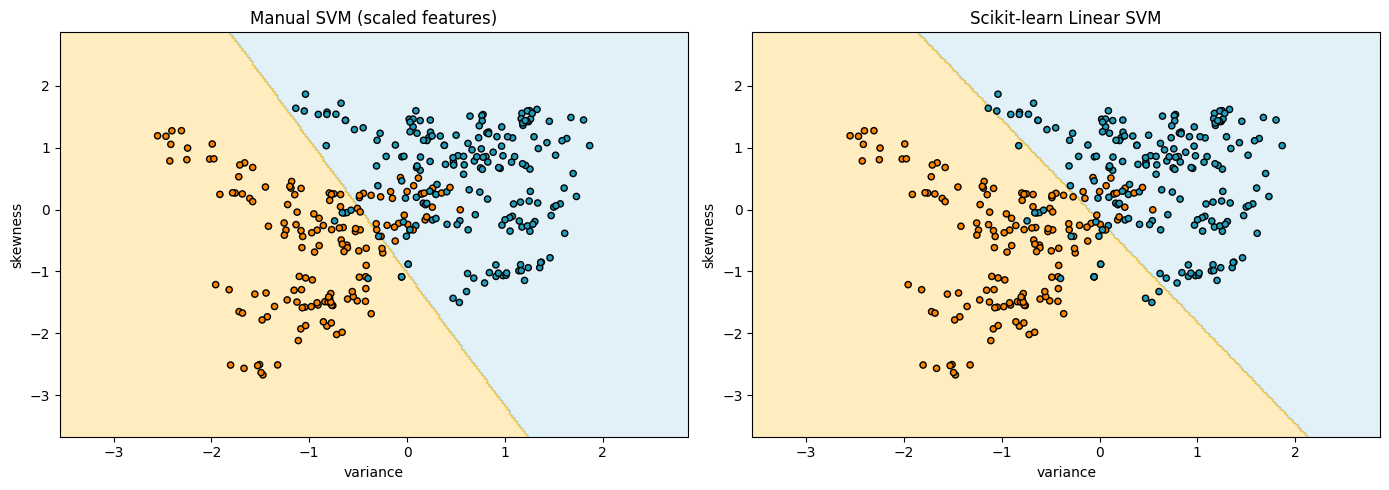

In [38]:
sk_svm = SVC(kernel="linear", C=1.0)
t0 = time.perf_counter()
sk_svm.fit(X2_train_scaled, y_train_svm)
sk_svm_train_time = time.perf_counter() - t0
sk_svm_pred = sk_svm.predict(X2_test_scaled)

print("Manual linear SVM accuracy:", round(accuracy_score(y_test_svm, manual_svm_pred), 4))
print("Scikit-learn linear SVM accuracy:", round(accuracy_score(y_test_svm, sk_svm_pred), 4))
print("Scikit-learn training time (s):", round(sk_svm_train_time, 6))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_boundary(manual_svm, X2_test_scaled, y_test_svm, "Manual SVM (scaled features)", ax=axes[0])
plot_boundary(sk_svm, X2_test_scaled, y_test_svm, "Scikit-learn Linear SVM", ax=axes[1])
plt.tight_layout()
plt.show()

In [39]:
svm_rows = []
for C in [0.1, 1.0, 10.0]:
    for lr in [0.001, 0.005]:
        for iterations in [1000, 3000]:
            model = ManualLinearSVM(C=C, learning_rate=lr, n_iter=iterations)
            start = time.perf_counter()
            model.fit(X2_train_scaled, y_train_svm)
            train_seconds = time.perf_counter() - start
            pred = model.predict(X2_test_scaled)
            svm_rows.append({
                "C": C, "learning_rate": lr, "iterations": iterations,
                "accuracy": accuracy_score(y_test_svm, pred),
                "train_time_s": train_seconds
            })
display(pd.DataFrame(svm_rows).sort_values("accuracy", ascending=False).reset_index(drop=True))

,C,learning_rate,iterations,accuracy,train_time_s
0,10.0,0.005,3000,0.895044,0.328493
1,10.0,0.001,3000,0.895044,0.313615
2,10.0,0.005,1000,0.895044,0.102360
3,0.1,0.001,1000,0.892128,0.165670
4,10.0,0.001,1000,0.892128,0.124585
5,1.0,0.001,1000,0.892128,0.152789
6,1.0,0.005,1000,0.886297,0.127279
7,1.0,0.001,3000,0.886297,0.384742
8,0.1,0.001,3000,0.880466,0.405490
9,1.0,0.005,3000,0.880466,0.380748


In [40]:
X_moons, y_moons = make_moons(n_samples=600, noise=0.22, random_state=RANDOM_STATE)
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.25, random_state=RANDOM_STATE, stratify=y_moons
)
moon_scaler = StandardScaler()
X_moons_train_scaled = moon_scaler.fit_transform(X_moons_train)
X_moons_test_scaled = moon_scaler.transform(X_moons_test)

kernel_models = {}
kernel_rows = []
for kernel in ["linear", "poly", "rbf"]:
    model = SVC(kernel=kernel, C=1.0, degree=3, gamma="scale")
    start = time.perf_counter()
    model.fit(X_moons_train_scaled, y_moons_train)
    train_seconds = time.perf_counter() - start
    pred = model.predict(X_moons_test_scaled)
    kernel_models[kernel] = model
    kernel_rows.append({
        "kernel": kernel,
        "accuracy": accuracy_score(y_moons_test, pred),
        "precision": precision_score(y_moons_test, pred, zero_division=0),
        "recall": recall_score(y_moons_test, pred, zero_division=0),
        "f1": f1_score(y_moons_test, pred, zero_division=0),
        "train_time_s": train_seconds
    })
display(pd.DataFrame(kernel_rows).sort_values("f1", ascending=False).reset_index(drop=True))

,kernel,accuracy,precision,recall,f1,train_time_s
0,rbf,0.940000,0.912500,0.973333,0.941935,0.003168
1,poly,0.873333,0.888889,0.853333,0.870748,0.003132
2,linear,0.866667,0.848101,0.893333,0.870130,0.003480


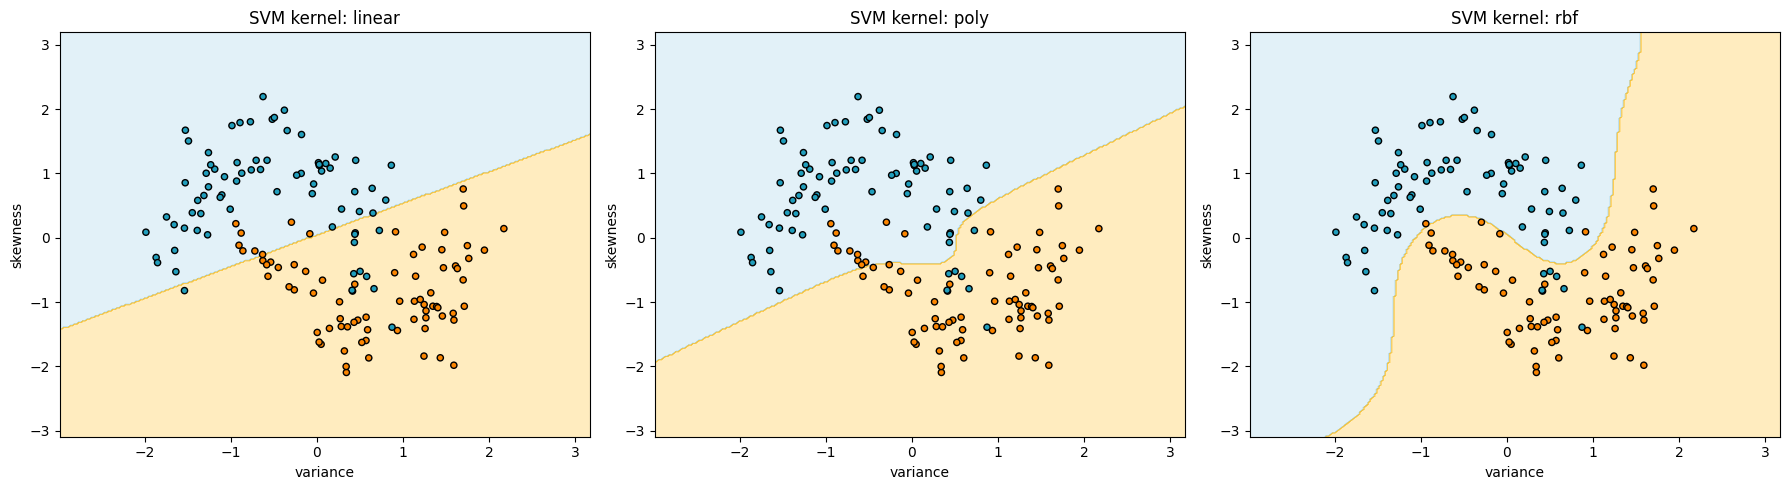

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, kernel in zip(axes, ["linear", "poly", "rbf"]):
    plot_boundary(kernel_models[kernel], X_moons_test_scaled, y_moons_test,
                  f"SVM kernel: {kernel}", ax=ax)
plt.tight_layout()
plt.show()

**Explanation:** A linear SVM separates classes with a straight line in the original feature space. Polynomial and RBF kernels can represent curved boundaries by comparing examples through a kernel function. When the class pattern is nonlinear, these kernels can fit the shape better, although overly flexible boundaries may overfit.

In [42]:
X_all = df[["variance", "skewness", "curtosis", "entropy"]].to_numpy(dtype=float)
y_all = df["class"].to_numpy(dtype=int)

X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all, y_all, test_size=0.25, random_state=RANDOM_STATE, stratify=y_all
)

scaler_all = StandardScaler()
X_train_all_scaled = scaler_all.fit_transform(X_train_all)
X_test_all_scaled = scaler_all.transform(X_test_all)

y_train_all_pm = np.where(y_train_all == 1, 1, -1)
y_test_all_pm = np.where(y_test_all == 1, 1, -1)

models = {
    "Manual Decision Tree (Gini, depth 4)": (
        ManualDecisionTree(criterion="gini", max_depth=4), X_train_all, X_test_all,
        y_train_all, y_test_all
    ),
    "Sklearn Decision Tree (Gini, depth 4)": (
        DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE),
        X_train_all, X_test_all, y_train_all, y_test_all
    ),
    "Manual Linear SVM": (
        ManualLinearSVM(C=1.0, learning_rate=0.005, n_iter=4000),
        X_train_all_scaled, X_test_all_scaled, y_train_all_pm, y_test_all_pm
    ),
    "Sklearn Linear SVM": (
        SVC(kernel="linear", C=1.0),
        X_train_all_scaled, X_test_all_scaled, y_train_all_pm, y_test_all_pm
    ),
    "Sklearn RBF SVM": (
        SVC(kernel="rbf", C=1.0, gamma="scale"),
        X_train_all_scaled, X_test_all_scaled, y_train_all_pm, y_test_all_pm
    ),
}

results = []
fitted_models = {}
for name, (model, Xtr, Xte, ytr, yte) in models.items():
    start = time.perf_counter()
    model.fit(Xtr, ytr)
    train_seconds = time.perf_counter() - start

    start = time.perf_counter()
    pred = model.predict(Xte)
    prediction_seconds = time.perf_counter() - start

    # Map SVM predictions back to original 0/1 labels for consistent metrics.
    if "SVM" in name:
        pred_for_metrics = np.where(pred == 1, 1, 0)
        true_for_metrics = np.where(yte == 1, 1, 0)
    else:
        pred_for_metrics = pred
        true_for_metrics = yte

    results.append({
        "model": name,
        "accuracy": accuracy_score(true_for_metrics, pred_for_metrics),
        "precision": precision_score(true_for_metrics, pred_for_metrics, zero_division=0),
        "recall": recall_score(true_for_metrics, pred_for_metrics, zero_division=0),
        "f1_score": f1_score(true_for_metrics, pred_for_metrics, zero_division=0),
        "training_time_s": train_seconds,
        "prediction_time_s": prediction_seconds
    })
    fitted_models[name] = model

results_df = pd.DataFrame(results).sort_values("f1_score", ascending=False).reset_index(drop=True)
display(results_df)

,model,accuracy,precision,recall,f1_score,training_time_s,prediction_time_s
0,Sklearn RBF SVM,1.000000,1.000000,1.000000,1.000000,0.005768,0.001839
1,Sklearn Linear SVM,0.976676,0.950000,1.000000,0.974359,0.008123,0.000840
2,"Manual Decision Tree (Gini, depth 4)",0.970845,0.943750,0.993421,0.967949,1.256355,0.000573
3,"Sklearn Decision Tree (Gini, depth 4)",0.970845,0.943750,0.993421,0.967949,0.004627,0.000325
4,Manual Linear SVM,0.909621,0.948148,0.842105,0.891986,0.524743,0.000033


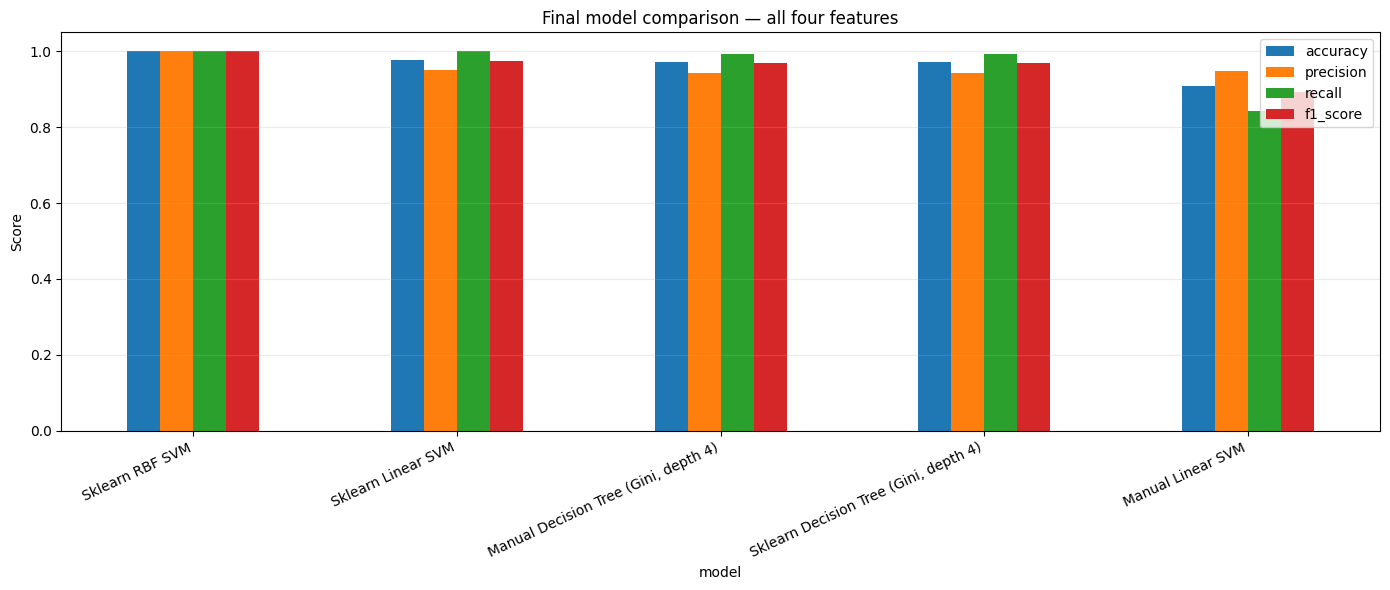

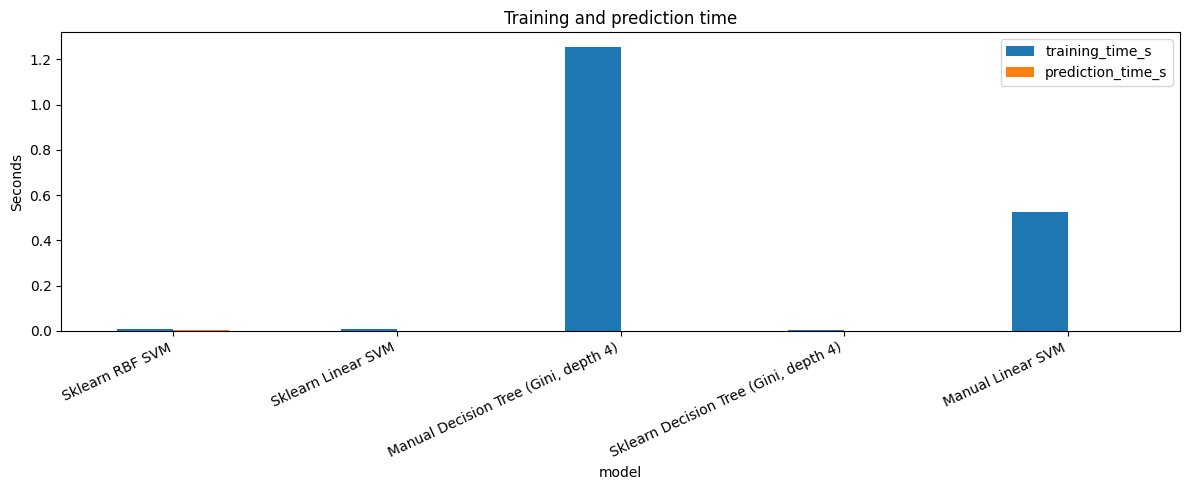

In [43]:
metric_columns = ["accuracy", "precision", "recall", "f1_score"]
results_df.set_index("model")[metric_columns].plot(kind="bar", figsize=(14, 6), ylim=(0, 1.05))
plt.ylabel("Score")
plt.title("Final model comparison — all four features")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

results_df.set_index("model")[["training_time_s", "prediction_time_s"]].plot(kind="bar", figsize=(12, 5))
plt.ylabel("Seconds")
plt.title("Training and prediction time")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [45]:
best_row = results_df.iloc[0]
print("Highest F1-score model:", best_row["model"])
print(f"F1-score: {best_row['f1_score']:.4f}")

Highest F1-score model: Sklearn RBF SVM
F1-score: 1.0000
